In [3]:
# Phase 6: Advanced Model Improvement

## Cybercrime Cash-Withdrawal Location Forecast

### Objectives
# 1. Improve classification performance across Low, Medium and High risk classes.
# 2. Address class imbalance using class-weighted algorithms.
# 3. Experiment with advanced classification models.
# 4. Evaluate models using chronological cross-validation.
# 5. Select the best model using validation Macro F1-score.
# 6. Compare the improved models against the existing baseline.

# All experiments use synthetic academic data.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
# Load dataset
df = pd.read_csv(
    "../data/raw/synthetic_atm_data.csv",
    parse_dates=["date"]
)

# Load existing model bundle
model_bundle = joblib.load(
    "../models/best_risk_classifier.joblib"
)

FEATURES = model_bundle["features"]
TARGET = model_bundle["target"]
CLASS_ORDER = model_bundle["class_order"]

best_model = model_bundle["model"]
preprocessor = best_model.named_steps["preprocessor"]

print("Dataset shape:", df.shape)
print("Number of features:", len(FEATURES))
print("Target:", TARGET)
print("Classes:", CLASS_ORDER)

Dataset shape: (6036, 21)
Number of features: 23
Target: target_risk
Classes: ['Low', 'Medium', 'High']


In [6]:
df = df.sort_values(
    ["date", "zone_id"]
).reset_index(drop=True)

df["withdrawals_per_atm"] = (
    df["withdrawal_count"] /
    df["atm_count"].replace(0, np.nan)
)

df["unusual_activity_ratio"] = (
    df["unusual_activity_count"] /
    df["withdrawal_count"].replace(0, np.nan)
)

df["avg_daily_incidents_30d"] = (
    df["incidents_sum_30d"] / 30
)

df["withdrawal_amount_per_atm"] = (
    df["total_withdrawal_amount"] /
    df["atm_count"].replace(0, np.nan)
)

day_index = (
    df["date"] - pd.Timestamp("2025-01-01")
).dt.days

df["season_30d_sin"] = np.sin(
    2 * np.pi * day_index / 30
)

df["season_30d_cos"] = np.cos(
    2 * np.pi * day_index / 30
)

df = df.replace([np.inf, -np.inf], np.nan)

print("Feature engineering completed!")
print("Missing values in selected features:",
      df[FEATURES].isna().sum().sum())

Feature engineering completed!
Missing values in selected features: 0


In [7]:
unique_dates = np.sort(df["date"].unique())

split_index = int(len(unique_dates) * 0.80)

test_start = pd.Timestamp(unique_dates[split_index])
train_end = test_start - pd.Timedelta(days=7)

train_mask = df["date"] < train_end
test_mask = df["date"] >= test_start

X_train = df.loc[train_mask, FEATURES].copy()
X_test = df.loc[test_mask, FEATURES].copy()

y_train = df.loc[train_mask, TARGET].astype(str)
y_test = df.loc[test_mask, TARGET].astype(str)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining period:")
print(df.loc[train_mask, "date"].min(),
      "to", df.loc[train_mask, "date"].max())

print("\nTesting period:")
print(df.loc[test_mask, "date"].min(),
      "to", df.loc[test_mask, "date"].max())

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training shape: (4740, 23)
Testing shape: (1212, 23)

Training period:
2025-01-31 00:00:00 to 2026-03-01 00:00:00

Testing period:
2026-03-09 00:00:00 to 2026-06-17 00:00:00

Training class distribution:
target_risk
Medium    1929
High      1719
Low       1092
Name: count, dtype: int64

Testing class distribution:
target_risk
Medium    486
High      414
Low       312
Name: count, dtype: int64


In [ ]:
## Step 2: Time-Series Cross-Validation

# We use expanding-window time-series cross-validation with:
# - 5 validation folds
# - 30 days per validation fold
# - 7-day gap between training and validation
# - All geographical zones from the same date kept together

# This preserves chronological order and reduces temporal leakage.

In [8]:
# Extract dates from training data
train_dates = pd.to_datetime(
    df.loc[train_mask, "date"]
).reset_index(drop=True)

unique_train_dates = np.sort(train_dates.unique())

# Five expanding-window folds
tscv = TimeSeriesSplit(
    n_splits=5,
    test_size=30,
    gap=7
)

cv_splits = []

for fold, (train_date_idx, val_date_idx) in enumerate(
    tscv.split(unique_train_dates), start=1
):

    fold_train_dates = unique_train_dates[train_date_idx]
    fold_val_dates = unique_train_dates[val_date_idx]

    # Keep every zone belonging to each selected date
    fold_train_idx = np.flatnonzero(
        train_dates.isin(fold_train_dates).to_numpy()
    )

    fold_val_idx = np.flatnonzero(
        train_dates.isin(fold_val_dates).to_numpy()
    )

    cv_splits.append((fold_train_idx, fold_val_idx))

    print(f"\nFold {fold}")

    print(
        "Training:",
        train_dates.iloc[fold_train_idx].min(),
        "to",
        train_dates.iloc[fold_train_idx].max()
    )

    print(
        "Validation:",
        train_dates.iloc[fold_val_idx].min(),
        "to",
        train_dates.iloc[fold_val_idx].max()
    )

    print("Training samples:", len(fold_train_idx))
    print("Validation samples:", len(fold_val_idx))

print("\nTotal CV folds:", len(cv_splits))


Fold 1
Training: 2025-01-31 00:00:00 to 2025-09-25 00:00:00
Validation: 2025-10-03 00:00:00 to 2025-11-01 00:00:00
Training samples: 2856
Validation samples: 360

Fold 2
Training: 2025-01-31 00:00:00 to 2025-10-25 00:00:00
Validation: 2025-11-02 00:00:00 to 2025-12-01 00:00:00
Training samples: 3216
Validation samples: 360

Fold 3
Training: 2025-01-31 00:00:00 to 2025-11-24 00:00:00
Validation: 2025-12-02 00:00:00 to 2025-12-31 00:00:00
Training samples: 3576
Validation samples: 360

Fold 4
Training: 2025-01-31 00:00:00 to 2025-12-24 00:00:00
Validation: 2026-01-01 00:00:00 to 2026-01-30 00:00:00
Training samples: 3936
Validation samples: 360

Fold 5
Training: 2025-01-31 00:00:00 to 2026-01-23 00:00:00
Validation: 2026-01-31 00:00:00 to 2026-03-01 00:00:00
Training samples: 4296
Validation samples: 360

Total CV folds: 5


In [9]:
for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):

    train_fold_dates = set(train_dates.iloc[train_idx])
    val_fold_dates = set(train_dates.iloc[val_idx])

    assert train_fold_dates.isdisjoint(val_fold_dates)

    train_last_date = max(train_fold_dates)
    val_first_date = min(val_fold_dates)

    gap_days = (
        val_first_date - train_last_date
    ).days - 1

    assert gap_days >= 7

print("All cross-validation folds passed!")
print("No shared dates between training and validation.")
print("Seven-day embargo verified.")

All cross-validation folds passed!
No shared dates between training and validation.
Seven-day embargo verified.


In [ ]:
## Step 3: Advanced Model Training

# We evaluate four classification algorithms:

# 1. Class-weighted Logistic Regression
# 2. Balanced Random Forest
# 3. Extra Trees Classifier
# 4. Class-weighted Support Vector Machine

# The models are evaluated using five-fold chronological
# cross-validation. Macro F1-score is the primary selection metric.

In [10]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

models = {
    "Balanced Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        random_state=42
    ),

    "Balanced Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced_subsample",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Balanced Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        class_weight="balanced",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Balanced SVM": SVC(
        class_weight="balanced",
        probability=True,
        random_state=42
    )
}

print("Four advanced models configured successfully!")

Four advanced models configured successfully!


In [11]:
cv_results = []

for model_name, classifier in models.items():

    print(f"\nEvaluating: {model_name}")

    fold_scores = []

    for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):

        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]

        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        # Clone the existing preprocessing pipeline
        fold_preprocessor = clone(preprocessor)

        X_fold_train_processed = fold_preprocessor.fit_transform(
            X_fold_train
        )

        X_fold_val_processed = fold_preprocessor.transform(
            X_fold_val
        )

        # Train classifier
        fold_model = clone(classifier)

        fold_model.fit(
            X_fold_train_processed,
            y_fold_train
        )

        predictions = fold_model.predict(
            X_fold_val_processed
        )

        score = f1_score(
            y_fold_val,
            predictions,
            average="macro",
            zero_division=0
        )

        fold_scores.append(score)

        print(f"Fold {fold}: Macro F1 = {score:.4f}")

    cv_results.append({
        "Model": model_name,
        "Mean Macro F1": np.mean(fold_scores),
        "Std Macro F1": np.std(fold_scores)
    })

print("\nAll models evaluated!")


Evaluating: Balanced Logistic Regression
Fold 1: Macro F1 = 0.3878
Fold 2: Macro F1 = 0.4016
Fold 3: Macro F1 = 0.4093
Fold 4: Macro F1 = 0.3810
Fold 5: Macro F1 = 0.3800

Evaluating: Balanced Random Forest
Fold 1: Macro F1 = 0.4131
Fold 2: Macro F1 = 0.3224
Fold 3: Macro F1 = 0.3589
Fold 4: Macro F1 = 0.3033
Fold 5: Macro F1 = 0.4100

Evaluating: Balanced Extra Trees
Fold 1: Macro F1 = 0.3970
Fold 2: Macro F1 = 0.3008
Fold 3: Macro F1 = 0.3673
Fold 4: Macro F1 = 0.3682
Fold 5: Macro F1 = 0.3919

Evaluating: Balanced SVM
Fold 1: Macro F1 = 0.4702
Fold 2: Macro F1 = 0.3489
Fold 3: Macro F1 = 0.3964
Fold 4: Macro F1 = 0.3536
Fold 5: Macro F1 = 0.3946

All models evaluated!


In [12]:
cv_comparison = pd.DataFrame(cv_results)

cv_comparison = cv_comparison.sort_values(
    "Mean Macro F1",
    ascending=False
).reset_index(drop=True)

print(cv_comparison.to_string(index=False))

                       Model  Mean Macro F1  Std Macro F1
                Balanced SVM       0.392751      0.043516
Balanced Logistic Regression       0.391929      0.011612
        Balanced Extra Trees       0.365041      0.034325
      Balanced Random Forest       0.361543      0.044602


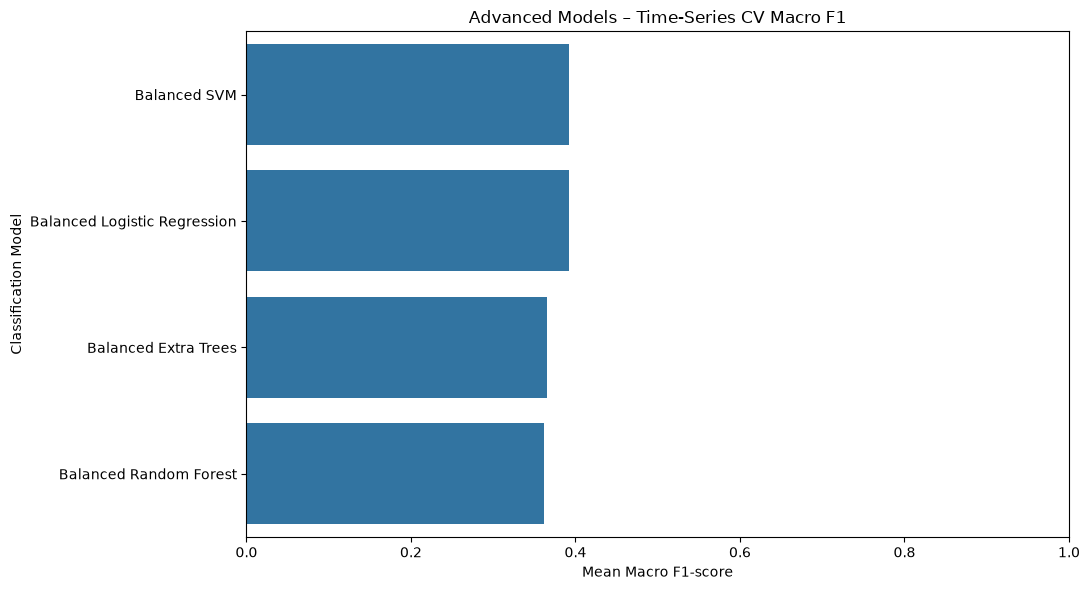

In [13]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=cv_comparison,
    x="Mean Macro F1",
    y="Model"
)

plt.title("Advanced Models – Time-Series CV Macro F1")
plt.xlabel("Mean Macro F1-score")
plt.ylabel("Classification Model")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

In [ ]:
# Step 4 – Hyperparameter optimization
# Now we'll tune the two strongest candidates:
# - Balanced Logistic Regression
# - Balanced SVM
# We'll use GridSearchCV with your existing chronological folds.

In [19]:
from sklearn.pipeline import Pipeline

lr_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=3000,
        random_state=42
    ))
])

svm_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", SVC(
        probability=False,
        random_state=42
    ))
])

print("Model pipelines created successfully!")

Model pipelines created successfully!


In [20]:
lr_param_grid = {
    "classifier__C": [0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"]
}

svm_param_grid = {
    "classifier__C": [0.1, 1, 10],
    "classifier__kernel": ["linear", "rbf"],
    "classifier__class_weight": [None, "balanced"]
}

print("Hyperparameter grids configured!")

Hyperparameter grids configured!


In [21]:
lr_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    scoring="f1_macro",
    cv=cv_splits,
    n_jobs=-1,
    verbose=1,
    refit=True
)

svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    scoring="f1_macro",
    cv=cv_splits,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("Tuning Logistic Regression...")
lr_search.fit(X_train, y_train)

print("\nTuning SVM...")
svm_search.fit(X_train, y_train)

print("\nHyperparameter optimization completed!")

Tuning Logistic Regression...
Fitting 5 folds for each of 6 candidates, totalling 30 fits

Tuning SVM...
Fitting 5 folds for each of 12 candidates, totalling 60 fits

Hyperparameter optimization completed!


In [22]:
# Compare optimized models

tuned_results = pd.DataFrame([
    {
        "Model": "Tuned Logistic Regression",
        "Best CV Macro F1": max(
            lr_search.cv_results_["mean_test_score"]
        ),
        "Best Parameters": lr_search.best_params_
    },
    {
        "Model": "Tuned SVM",
        "Best CV Macro F1": max(
            svm_search.cv_results_["mean_test_score"]
        ),
        "Best Parameters": svm_search.best_params_
    }
])

tuned_results = tuned_results.sort_values(
    "Best CV Macro F1",
    ascending=False
).reset_index(drop=True)

print(tuned_results.to_string(index=False))

                    Model  Best CV Macro F1                                                                           Best Parameters
Tuned Logistic Regression          0.401695                            {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}
                Tuned SVM          0.392751 {'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__kernel': 'rbf'}


In [ ]:
# ## Step 5: Final Candidate Evaluation

# The tuned Logistic Regression model is selected based on
# the highest chronological cross-validation Macro F1-score.

# The held-out test set is used only for final evaluation.

In [23]:
# Select model using validation performance
final_model = lr_search.best_estimator_

# Predict on untouched test data
y_pred = final_model.predict(X_test)

# Prediction probabilities
y_prob = final_model.predict_proba(X_test)

print("Selected model: Tuned Logistic Regression")
print("Best CV Macro F1:", round(lr_search.best_score_, 4))
print("Test predictions generated successfully!")

Selected model: Tuned Logistic Regression
Best CV Macro F1: 0.4017
Test predictions generated successfully!


In [24]:
final_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),

    "Balanced Accuracy": balanced_accuracy_score(
        y_test, y_pred
    ),

    "Macro Precision": precision_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    ),

    "Macro Recall": recall_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    ),

    "Macro F1": f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    ),

    "Weighted F1": f1_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        y_test,
        y_prob,
        multi_class="ovr",
        average="macro",
        labels=final_model.classes_
    )
}

print("FINAL TEST PERFORMANCE")

for metric, value in final_metrics.items():
    print(f"{metric}: {value:.4f}")

FINAL TEST PERFORMANCE
Accuracy: 0.4208
Balanced Accuracy: 0.4520
Macro Precision: 0.4236
Macro Recall: 0.4520
Macro F1: 0.4100
Weighted F1: 0.3954
ROC-AUC: 0.6293


In [25]:
print(
    classification_report(
        y_test,
        y_pred,
        labels=CLASS_ORDER,
        zero_division=0
    )
)

              precision    recall  f1-score   support

         Low       0.38      0.63      0.48       312
      Medium       0.43      0.19      0.26       486
        High       0.46      0.54      0.49       414

    accuracy                           0.42      1212
   macro avg       0.42      0.45      0.41      1212
weighted avg       0.43      0.42      0.40      1212



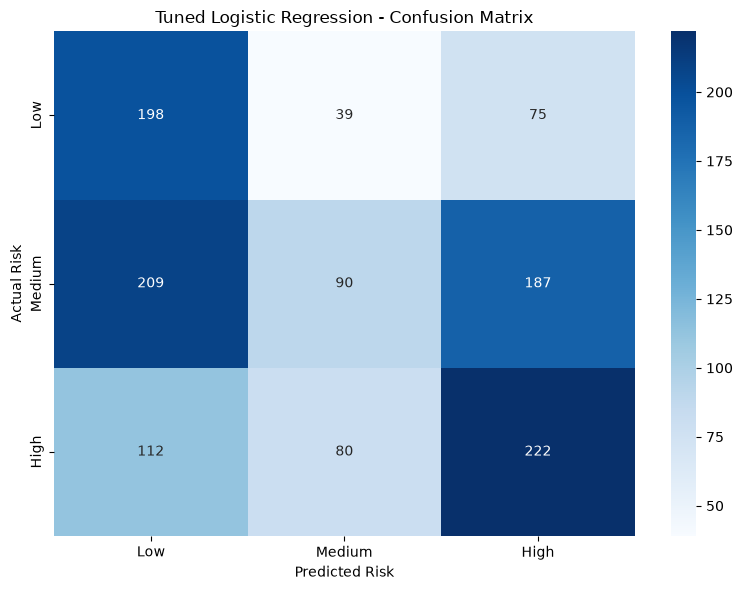

In [26]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=CLASS_ORDER
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_ORDER,
    yticklabels=CLASS_ORDER
)

plt.title("Tuned Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")

plt.tight_layout()
plt.show()

In [ ]:
# ## Phase 6.1: Decision Threshold Optimization

# A separate chronological calibration window is used to
# identify a suitable Medium-risk probability threshold.

# The final test dataset remains untouched throughout
# threshold selection.

In [27]:
# Get unique dates from the training period
training_dates = np.sort(X_train.index)

# Use the dates from the original dataset
train_period = df.loc[train_mask].copy()

unique_train_dates = np.sort(
    train_period["date"].unique()
)

# Reserve the final 30 days for calibration
calibration_start = pd.Timestamp(
    unique_train_dates[-30]
)

calibration_end = pd.Timestamp(
    unique_train_dates[-1]
)

# Apply a 7-day embargo
calibration_train_end = (
    calibration_start - pd.Timedelta(days=7)
)

cal_train_mask = (
    train_period["date"] < calibration_train_end
)

cal_validation_mask = (
    (train_period["date"] >= calibration_start) &
    (train_period["date"] <= calibration_end)
)

X_cal_train = train_period.loc[
    cal_train_mask, FEATURES
].copy()

y_cal_train = train_period.loc[
    cal_train_mask, TARGET
].astype(str)

X_calibration = train_period.loc[
    cal_validation_mask, FEATURES
].copy()

y_calibration = train_period.loc[
    cal_validation_mask, TARGET
].astype(str)

print("Calibration split created!")
print("Model training samples:", len(X_cal_train))
print("Calibration samples:", len(X_calibration))

print("\nCalibration period:")
print(
    train_period.loc[cal_validation_mask, "date"].min(),
    "to",
    train_period.loc[cal_validation_mask, "date"].max()
)

print("\nCalibration class distribution:")
print(y_calibration.value_counts())

Calibration split created!
Model training samples: 4296
Calibration samples: 360

Calibration period:
2026-01-31 00:00:00 to 2026-03-01 00:00:00

Calibration class distribution:
target_risk
Medium    152
High      111
Low        97
Name: count, dtype: int64


In [28]:
# Use the selected Logistic Regression configuration
calibration_model = clone(lr_search.best_estimator_)

# Fit only on the earlier training period
calibration_model.fit(
    X_cal_train,
    y_cal_train
)

# Generate probabilities for the calibration period
calibration_probabilities = (
    calibration_model.predict_proba(X_calibration)
)

print("Calibration model trained successfully!")
print("Probability matrix shape:",
      calibration_probabilities.shape)

print("Model classes:",
      calibration_model.classes_)

Calibration model trained successfully!
Probability matrix shape: (360, 3)
Model classes: ['High' 'Low' 'Medium']


In [29]:
# Align probabilities to CLASS_ORDER
aligned_probabilities = np.zeros(
    (len(X_calibration), len(CLASS_ORDER))
)

for i, class_name in enumerate(calibration_model.classes_):

    class_position = CLASS_ORDER.index(class_name)

    aligned_probabilities[:, class_position] = (
        calibration_probabilities[:, i]
    )

print("Probability columns aligned successfully!")
print("Class order:", CLASS_ORDER)
print("Probability shape:", aligned_probabilities.shape)

Probability columns aligned successfully!
Class order: ['Low', 'Medium', 'High']
Probability shape: (360, 3)


In [ ]:
# ## Step 4: Medium-Risk Threshold Optimization

# We investigate different Medium-risk probability thresholds
# using the chronological calibration dataset.

# The objective is to improve Medium-risk detection while
# maintaining overall classification performance.

# Threshold selection uses calibration data only.

In [30]:
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    recall_score
)

medium_index = CLASS_ORDER.index("Medium")

threshold_results = []

thresholds = np.arange(0.15, 0.61, 0.025)

for threshold in thresholds:

    adjusted_probabilities = aligned_probabilities.copy()

    # Select Medium when its probability exceeds the threshold
    predictions = []

    for row in adjusted_probabilities:

        if row[medium_index] >= threshold:
            predictions.append("Medium")

        else:
            other_indices = [
                i for i in range(len(CLASS_ORDER))
                if i != medium_index
            ]

            best_other = max(
                other_indices,
                key=lambda i: row[i]
            )

            predictions.append(CLASS_ORDER[best_other])

    macro_f1 = f1_score(
        y_calibration,
        predictions,
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    )

    medium_recall = recall_score(
        y_calibration,
        predictions,
        labels=["Medium"],
        average=None,
        zero_division=0
    )[0]

    balanced_acc = balanced_accuracy_score(
        y_calibration,
        predictions
    )

    threshold_results.append({
        "Threshold": threshold,
        "Macro F1": macro_f1,
        "Medium Recall": medium_recall,
        "Balanced Accuracy": balanced_acc
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.to_string(index=False))

 Threshold  Macro F1  Medium Recall  Balanced Accuracy
     0.150  0.197917       1.000000           0.333333
     0.175  0.197917       1.000000           0.333333
     0.200  0.204256       1.000000           0.336336
     0.225  0.230815       0.980263           0.344772
     0.250  0.240468       0.894737           0.331279
     0.275  0.312901       0.782895           0.358795
     0.300  0.343654       0.644737           0.365527
     0.325  0.375853       0.427632           0.379874
     0.350  0.360200       0.276316           0.372375
     0.375  0.374624       0.164474           0.417538
     0.400  0.338869       0.072368           0.413894
     0.425  0.316955       0.026316           0.411855
     0.450  0.312458       0.006579           0.421592
     0.475  0.307606       0.000000           0.419399
     0.500  0.307606       0.000000           0.419399
     0.525  0.307606       0.000000           0.419399
     0.550  0.307606       0.000000           0.419399
     0.575

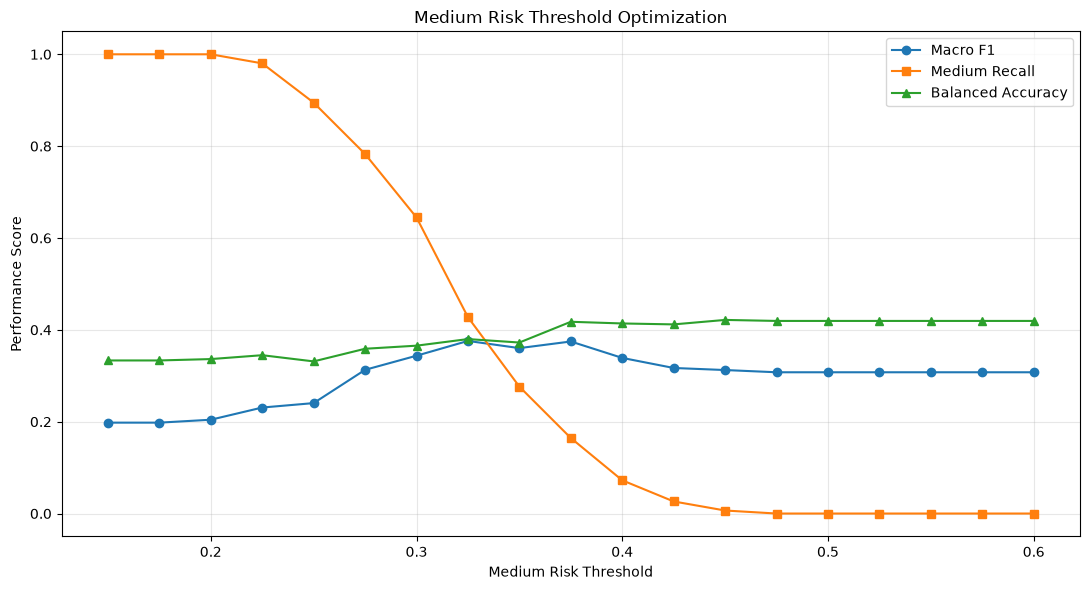

In [31]:
plt.figure(figsize=(11, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Macro F1"],
    marker="o",
    label="Macro F1"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Medium Recall"],
    marker="s",
    label="Medium Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Balanced Accuracy"],
    marker="^",
    label="Balanced Accuracy"
)

plt.xlabel("Medium Risk Threshold")
plt.ylabel("Performance Score")
plt.title("Medium Risk Threshold Optimization")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
best_threshold_row = threshold_df.loc[
    threshold_df["Macro F1"].idxmax()
]

best_medium_threshold = best_threshold_row["Threshold"]

print("Best Medium Threshold:",
      round(best_medium_threshold, 3))

print("Calibration Macro F1:",
      round(best_threshold_row["Macro F1"], 4))

print("Calibration Medium Recall:",
      round(best_threshold_row["Medium Recall"], 4))

print("Calibration Balanced Accuracy:",
      round(best_threshold_row["Balanced Accuracy"], 4))

Best Medium Threshold: 0.325
Calibration Macro F1: 0.3759
Calibration Medium Recall: 0.4276
Calibration Balanced Accuracy: 0.3799


In [33]:
# Original argmax predictions
baseline_predictions = np.array(CLASS_ORDER)[
    np.argmax(aligned_probabilities, axis=1)
]

# Threshold-based predictions
threshold_predictions = []

for row in aligned_probabilities:

    if row[medium_index] >= best_medium_threshold:
        threshold_predictions.append("Medium")
    else:
        other_indices = [
            i for i in range(len(CLASS_ORDER))
            if i != medium_index
        ]

        best_other = max(
            other_indices,
            key=lambda i: row[i]
        )

        threshold_predictions.append(CLASS_ORDER[best_other])

threshold_predictions = np.array(threshold_predictions)

# Compare strategies
comparison = []

for name, predictions in [
    ("Original Argmax", baseline_predictions),
    ("Optimized Threshold", threshold_predictions)
]:

    comparison.append({
        "Strategy": name,
        "Accuracy": accuracy_score(y_calibration, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_calibration, predictions
        ),
        "Macro F1": f1_score(
            y_calibration, predictions,
            average="macro",
            zero_division=0
        ),
        "Medium Recall": recall_score(
            y_calibration, predictions,
            labels=["Medium"],
            average=None,
            zero_division=0
        )[0]
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.to_string(index=False))

           Strategy  Accuracy  Balanced Accuracy  Macro F1  Medium Recall
    Original Argmax  0.386111           0.423322  0.370650       0.131579
Optimized Threshold  0.391667           0.379874  0.375853       0.427632


In [34]:
print("ORIGINAL ARGMAX REPORT")
print(classification_report(
    y_calibration,
    baseline_predictions,
    labels=CLASS_ORDER,
    zero_division=0
))

print("\nOPTIMIZED THRESHOLD REPORT")
print(classification_report(
    y_calibration,
    threshold_predictions,
    labels=CLASS_ORDER,
    zero_division=0
))

ORIGINAL ARGMAX REPORT
              precision    recall  f1-score   support

         Low       0.33      0.53      0.41        97
      Medium       0.42      0.13      0.20       152
        High       0.43      0.61      0.51       111

    accuracy                           0.39       360
   macro avg       0.39      0.42      0.37       360
weighted avg       0.40      0.39      0.35       360


OPTIMIZED THRESHOLD REPORT
              precision    recall  f1-score   support

         Low       0.26      0.22      0.23        97
      Medium       0.42      0.43      0.42       152
        High       0.44      0.50      0.47       111

    accuracy                           0.39       360
   macro avg       0.37      0.38      0.38       360
weighted avg       0.38      0.39      0.39       360



In [35]:
# Use probabilities from the final model
# The final model was trained on the complete training set.

test_threshold_predictions = []

for row in y_prob:

    if row[medium_index] >= best_medium_threshold:
        test_threshold_predictions.append("Medium")

    else:
        other_indices = [
            i for i in range(len(CLASS_ORDER))
            if i != medium_index
        ]

        best_other = max(
            other_indices,
            key=lambda i: row[i]
        )

        test_threshold_predictions.append(
            CLASS_ORDER[best_other]
        )

test_threshold_predictions = np.array(
    test_threshold_predictions
)

print("Threshold-based test predictions generated!")
print("Threshold:", best_medium_threshold)

Threshold-based test predictions generated!
Threshold: 0.32499999999999996


In [36]:
test_comparison = []

for name, predictions in [
    ("Original Argmax", y_pred),
    ("Threshold 0.325", test_threshold_predictions)
]:

    test_comparison.append({
        "Strategy": name,

        "Accuracy": accuracy_score(
            y_test, predictions
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),

        "Macro F1": f1_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        ),

        "Medium Recall": recall_score(
            y_test, predictions,
            labels=["Medium"],
            average=None,
            zero_division=0
        )[0]
    })

test_comparison_df = pd.DataFrame(test_comparison)

print(test_comparison_df.to_string(index=False))

       Strategy  Accuracy  Balanced Accuracy  Macro F1  Medium Recall
Original Argmax  0.420792           0.452011  0.409986       0.185185
Threshold 0.325  0.312706           0.291611  0.270371       0.551440


In [37]:
print("ORIGINAL ARGMAX - TEST REPORT")

print(classification_report(
    y_test,
    y_pred,
    labels=CLASS_ORDER,
    zero_division=0
))

print("\nTHRESHOLD 0.325 - TEST REPORT")

print(classification_report(
    y_test,
    test_threshold_predictions,
    labels=CLASS_ORDER,
    zero_division=0
))

ORIGINAL ARGMAX - TEST REPORT
              precision    recall  f1-score   support

         Low       0.38      0.63      0.48       312
      Medium       0.43      0.19      0.26       486
        High       0.46      0.54      0.49       414

    accuracy                           0.42      1212
   macro avg       0.42      0.45      0.41      1212
weighted avg       0.43      0.42      0.40      1212


THRESHOLD 0.325 - TEST REPORT
              precision    recall  f1-score   support

         Low       0.15      0.22      0.18       312
      Medium       0.41      0.55      0.47       486
        High       0.39      0.10      0.16       414

    accuracy                           0.31      1212
   macro avg       0.32      0.29      0.27      1212
weighted avg       0.34      0.31      0.29      1212



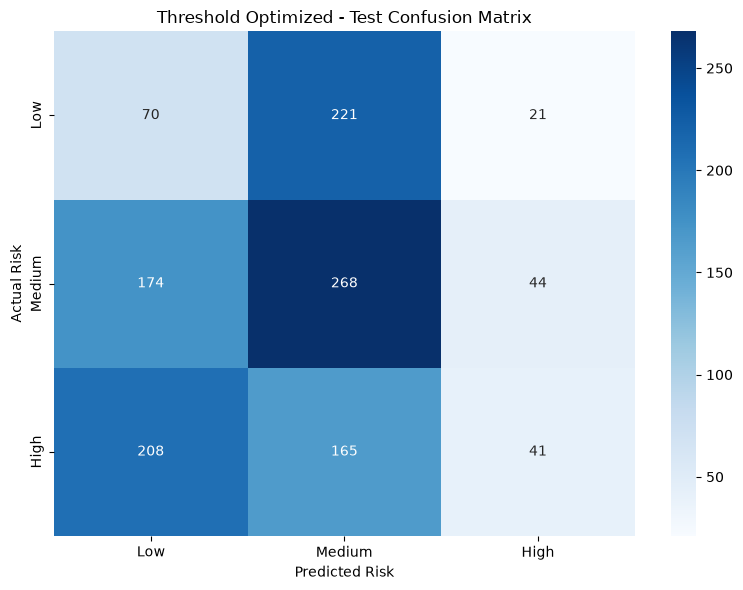

In [38]:
cm_threshold = confusion_matrix(
    y_test,
    test_threshold_predictions,
    labels=CLASS_ORDER
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_threshold,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_ORDER,
    yticklabels=CLASS_ORDER
)

plt.title("Threshold Optimized - Test Confusion Matrix")
plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")

plt.tight_layout()
plt.show()